In [4]:
import sys
import pandas as pd
import sklearn

print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("Scikit-learn version:", sklearn.__version__)

print("Jupyter Notebook is working successfully!")

Python version: 3.13.3
Pandas version: 3.1.1
Scikit-learn version: 1.9.1
Jupyter Notebook is working successfully!


In [9]:
# Step 1.8 - Load Amazon Beauty Reviews

from datasets import load_dataset
import pandas as pd
from pathlib import Path

# 1. Load the JSON Lines file directly
dataset = load_dataset(
    "json",
    data_files=(
        "hf://datasets/McAuley-Lab/Amazon-Reviews-2023/"
        "raw/review_categories/All_Beauty.jsonl"
    ),
    split="train",
    streaming=True
)

# 2. Collect 5,000 reviews
reviews = []

for review in dataset.take(5000):
    reviews.append({
        "text": review["text"],
        "rating": review["rating"]
    })

# 3. Convert to a DataFrame
df = pd.DataFrame(reviews)

# 4. Find the project folder
project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

data_path = project_path / "data"
data_path.mkdir(parents=True, exist_ok=True)

# 5. Save the dataset
file_path = data_path / "amazon_beauty_reviews.csv"
df.to_csv(file_path, index=False, encoding="utf-8")

# 6. Display results
print("Number of reviews:", len(df))
print("Saved to:", file_path)

size_mb = file_path.stat().st_size / (1024 * 1024)
print("Dataset size (MB):", round(size_mb, 2))

print("\nFirst five reviews:")
display(df.head())

print("\nRating distribution:")
print(df["rating"].value_counts().sort_index())

Number of reviews: 5000
Saved to: c:\Users\jyothi\sentiment-analysis-nlp\data\amazon_beauty_reviews.csv
Dataset size (MB): 1.86

First five reviews:


,text,rating
0,This spray is really nice. It smells really go...,5.0
1,"This product does what I need it to do, I just...",4.0
2,"Smells good, feels great!",5.0
3,Felt synthetic,1.0
4,Love it,5.0



Rating distribution:
rating
1.0     360
2.0     276
3.0     500
4.0    1000
5.0    2864
Name: count, dtype: int64


In [ ]:

# Step 1.9 - Data Cleaning and Sentiment Labelling

import pandas as pd
from pathlib import Path

# 1. Locate the project folder
project_path = Path.cwd()

if project_path.name == "notebooks":
    project_path = project_path.parent

# 2. Load our saved dataset
file_path = project_path / "data" / "amazon_beauty_reviews.csv"

df = pd.read_csv(file_path)

print("Original dataset shape:", df.shape)

# 3. Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# 4. Check duplicate reviews
print("\nDuplicate reviews:", df.duplicated(subset=["text"]).sum())

# 5. Remove missing values
df = df.dropna(subset=["text", "rating"]).copy()

# 6. Remove empty reviews
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""].copy()

# 7. Remove duplicate review texts
df = df.drop_duplicates(subset=["text"]).copy()

# 8. Convert star ratings into sentiment labels
def assign_sentiment(rating):
    if rating <= 2:
        return 0       # Negative
    elif rating == 3:
        return 1       # Neutral
    else:
        return 2       # Positive

df["sentiment"] = df["rating"].apply(assign_sentiment)

# 9. Display cleaned dataset
print("\nCleaned dataset shape:", df.shape)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts().sort_index())

print("\nFirst five cleaned reviews:")
display(df.head())

# 10. Save cleaned dataset
output_path = project_path / "data" / "cleaned_reviews.csv"

df.to_csv(output_path, index=False, encoding="utf-8")

print("\nCleaned dataset saved to:", output_path)


Original dataset shape: (5000, 2)

Missing values:
text      0
rating    0
dtype: int64

Duplicate reviews: 52

Cleaned dataset shape: (4947, 3)

Sentiment distribution:
sentiment
0     634
1     497
2    3816
Name: count, dtype: int64

First five cleaned reviews:


,text,rating,sentiment
0,This spray is really nice. It smells really go...,5.0,2
1,"This product does what I need it to do, I just...",4.0,2
2,"Smells good, feels great!",5.0,2
3,Felt synthetic,1.0,0
4,Love it,5.0,2



Cleaned dataset saved to: c:\Users\jyothi\sentiment-analysis-nlp\data\cleaned_reviews.csv


Matplotlib is building the font cache; this may take a moment.


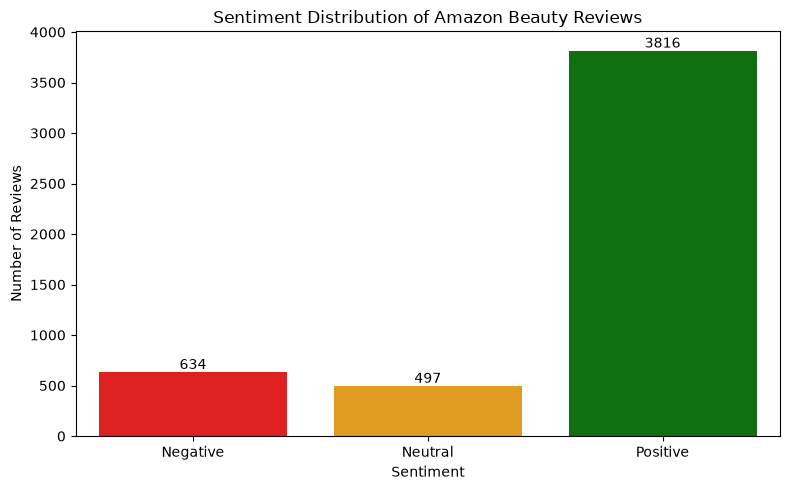

Chart saved to: c:\Users\jyothi\sentiment-analysis-nlp\data\sentiment_distribution.png


In [11]:

# Step 1.10 - Visualize Sentiment Distribution

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Count reviews in each sentiment class
sentiment_counts = df["sentiment"].value_counts().sort_index()

# 2. Define sentiment names
sentiment_names = ["Negative", "Neutral", "Positive"]

# 3. Create the bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_names,
    y=sentiment_counts.values,
    hue=sentiment_names,
    palette=["red", "orange", "green"],
    legend=False
)

# 4. Add chart labels
plt.title("Sentiment Distribution of Amazon Beauty Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

# 5. Display review counts above bars
for i, count in enumerate(sentiment_counts.values):
    plt.text(i, count + 30, str(count), ha="center")

plt.tight_layout()

# 6. Save the chart
output_path = project_path / "data" / "sentiment_distribution.png"

plt.savefig(output_path, dpi=300, bbox_inches="tight")

# 7. Display chart
plt.show()

print("Chart saved to:", output_path)


In [ ]:

# Step 1.11 - Train, Validation and Test Split

import pandas as pd
from sklearn.model_selection import train_test_split

# 1. Split dataset into 70% training and 30% temporary data
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["sentiment"]
)

# 2. Split temporary data equally into validation and test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["sentiment"]
)

# 3. Display dataset sizes
print("Training reviews:", len(train_df))
print("Validation reviews:", len(val_df))
print("Testing reviews:", len(test_df))

# 4. Display sentiment distribution in each dataset
print("\nTraining sentiment distribution:")
print(train_df["sentiment"].value_counts().sort_index())

print("\nValidation sentiment distribution:")
print(val_df["sentiment"].value_counts().sort_index())

print("\nTesting sentiment distribution:")
print(test_df["sentiment"].value_counts().sort_index())

# Define the folder for saving datasets
data_path = project_path / "data"
data_path.mkdir(parents=True, exist_ok=True)

# 5. Save all three datasets
train_df.to_csv(
    data_path / "train.csv",
    index=False
)

val_df.to_csv(
    data_path / "validation.csv",
    index=False
)

test_df.to_csv(
    data_path / "test.csv",
    index=False
)

print("\nAll datasets saved successfully!")


Training reviews: 3462
Validation reviews: 742
Testing reviews: 743

Training sentiment distribution:
sentiment
0     444
1     348
2    2670
Name: count, dtype: int64

Validation sentiment distribution:
sentiment
0     95
1     74
2    573
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
0     95
1     75
2    573
Name: count, dtype: int64

All datasets saved successfully!
